## Machine Learning AIMLZG565 Assignment - 2
Name: Sai Akshaya Kasireddi
BITS ID : 2026AK05083

# Performing Diabetes Classification Using Machine Learning

## 1. Introduction
Machine learning classification techniques can be used to study patterns in these indicators and classify individuals into diabetic and non-diabetic categories.This python assignment implements and compares five machine learning classification algorithms using the CDC Diabetes Health Indicators dataset.

## 2. Project Objectives

- Explore and understand the diabetes health indicators dataset.
- Perform data preprocessing and exploratory data analysis.
- Train five classification algorithms.
- Evaluate the models using six performance metrics.
- Compare the training and prediction runtime of each model.
- Analyse the performance of the models specifically for the diabetic class.
- Identify the most suitable model based on the evaluation results.

## 3. Dataset Description

The project uses the Diabetes Binary Health Indicators BRFSS 2015 dataset.

- Total records: 253,680
- Total columns: 22
- Input features: 21
- Target variable: Diabetes_binary
- Classification type: Binary classification

Target classes:
- 0: Non-diabetic
- 1: Diabetic

The dataset contains health-related indicators such as BMI, blood pressure, cholesterol, physical activity, general health, age, education and income.

### Importing the required libraries and loading dataset

In [4]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [5]:
# IMPORT LIBRARIES AND LOAD DATASET

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the downloaded CSV file
df = pd.read_csv(
    "diabetes_binary_health_indicators_BRFSS2015.csv"
)

print("The Dataset is loaded successfully!")

# Displaying the dataset dimensions
print("Dataset shape:", df.shape)

# Displaying the first five records
display(df.head())

The Dataset is loaded successfully!
Dataset shape: (253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


### Analysing the Dataset

In [7]:
# Checking the dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Checking the column names
print("\nColumn names:")
print(df.columns.tolist())

# Checking for missing values
print("\nMissing values:")
print(df.isnull().sum().sum())

# Checking for duplicates
print("\nDuplicate records:")
print(df.duplicated().sum())

# Checking for the target distribution
print("\nDiabetes distribution:")
print(df["Diabetes_binary"].value_counts())

Rows: 253680
Columns: 22

Column names:
['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Missing values:
0

Duplicate records:
24206

Diabetes distribution:
Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64


#### Observation on Duplicate Records

The dataset contains 24,206 duplicate rows and no missing values.

Duplicate records were retained during this analysis because identical combinations of health indicators may occur for different survey respondents. Since the dataset does not provide a unique respondent identifier to establish whether these are repeated observations of the same individual, removing them without further justification could result in unnecessary data loss.

Therefore, all original records were retained for model training and evaluation.

### Validating the dataset

In [10]:
# Separting the features and target variable
# Defining the Input variables
X = df.drop(columns=["Diabetes_binary"])

#Defining the Target variable
y = df["Diabetes_binary"]

# Displaying the dimensions
print("Input features (X):", X.shape)
print("Target variable (y):", y.shape)

print("\nNumber of input features:", X.shape[1])

# Validating the assignment requirements
assert X.shape[0] >= 500
assert X.shape[1] >= 12

# Checking the data types of the columns
print("\nData types:")
print(X.dtypes)

# Checking for unique values in each feature
print("\nUnique values:")
for column in X.columns:
    print(column, ":", X[column].nunique())

print("\nDataset meets the minimum assignment requirements!")

Input features (X): (253680, 21)
Target variable (y): (253680,)

Number of input features: 21

Data types:
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholConsump       float64
AnyHealthcare           float64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                     float64
Age                     float64
Education               float64
Income                  float64
dtype: object

Unique values:
HighBP : 2
HighChol : 2
CholCheck : 2
BMI : 84
Smoker : 2
Stroke : 2
HeartDiseaseorAttack : 2
PhysActivity : 2
Fruits : 2
Veggies : 2
HvyAlcoholConsump : 2
AnyHealthcare : 2
NoDocbcCost : 2
G

### Performing Exploratory Data Analysis(EDA)

Diabetes distribution:
Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

Percentage distribution:
Diabetes_binary
0.0    86.07
1.0    13.93
Name: proportion, dtype: float64


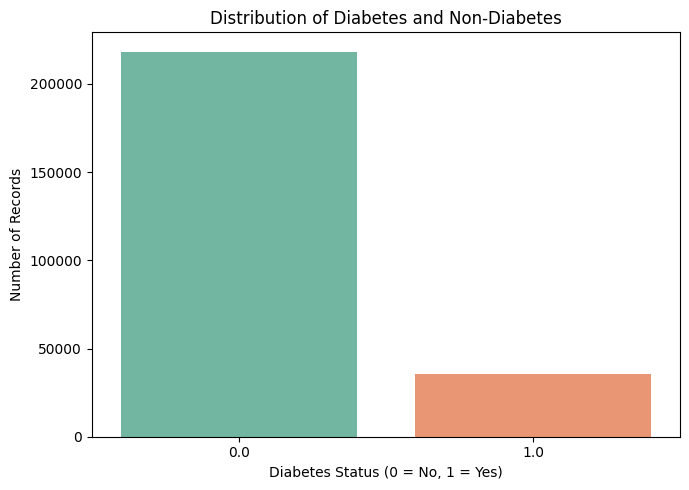

In [12]:
# Performing the Target Variable Analysis

# Counting the each target class
target_counts = y.value_counts().sort_index()

print("Diabetes distribution:")
print(target_counts)

# Calculating the percentage
target_percentage = y.value_counts(normalize=True).sort_index() * 100

print("\nPercentage distribution:")
print(target_percentage.round(2))

# Visualizing the target distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    hue=y,
    palette="Set2",
    legend=False
)

plt.title("Distribution of Diabetes and Non-Diabetes")
plt.xlabel("Diabetes Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

### Analysing BMI Distribution
Note:BMI is an one of the important health indicator in this dataset

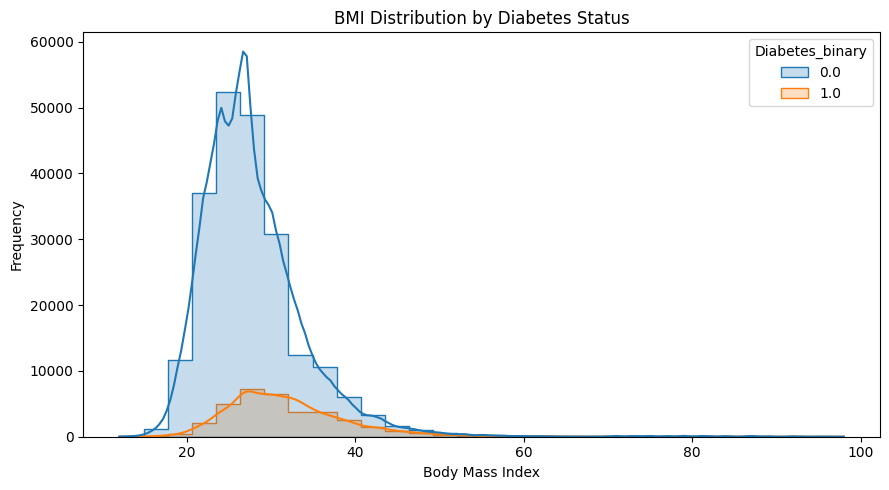

In [14]:
#BMI DISTRIBUTION

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="BMI",
    hue="Diabetes_binary",
    bins=30,
    kde=True,
    element="step"
)

plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("Body Mass Index")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Analysing the Genaral Health Variable

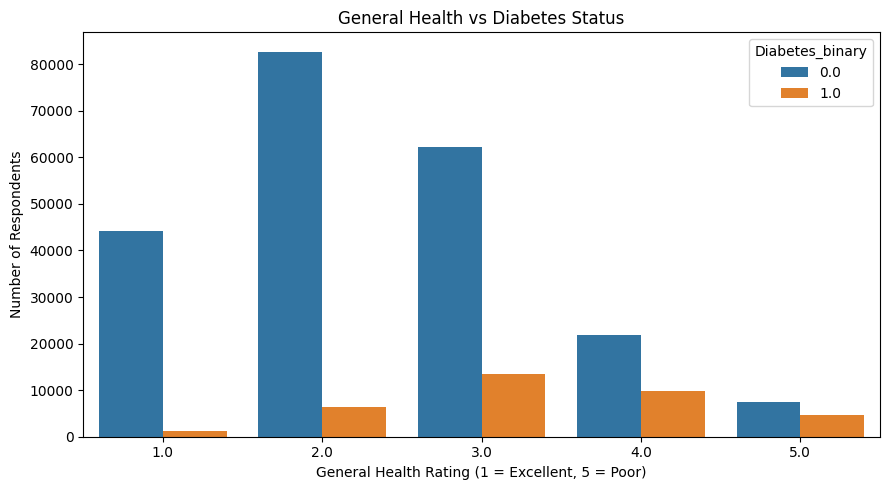

In [16]:
# GENERAL HEALTH ANALYSIS
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="GenHlth",
    hue="Diabetes_binary"
)

plt.title("General Health vs Diabetes Status")
plt.xlabel("General Health Rating (1 = Excellent, 5 = Poor)")
plt.ylabel("Number of Respondents")

plt.tight_layout()
plt.show()

### Checking relationship between numerical and encoded features

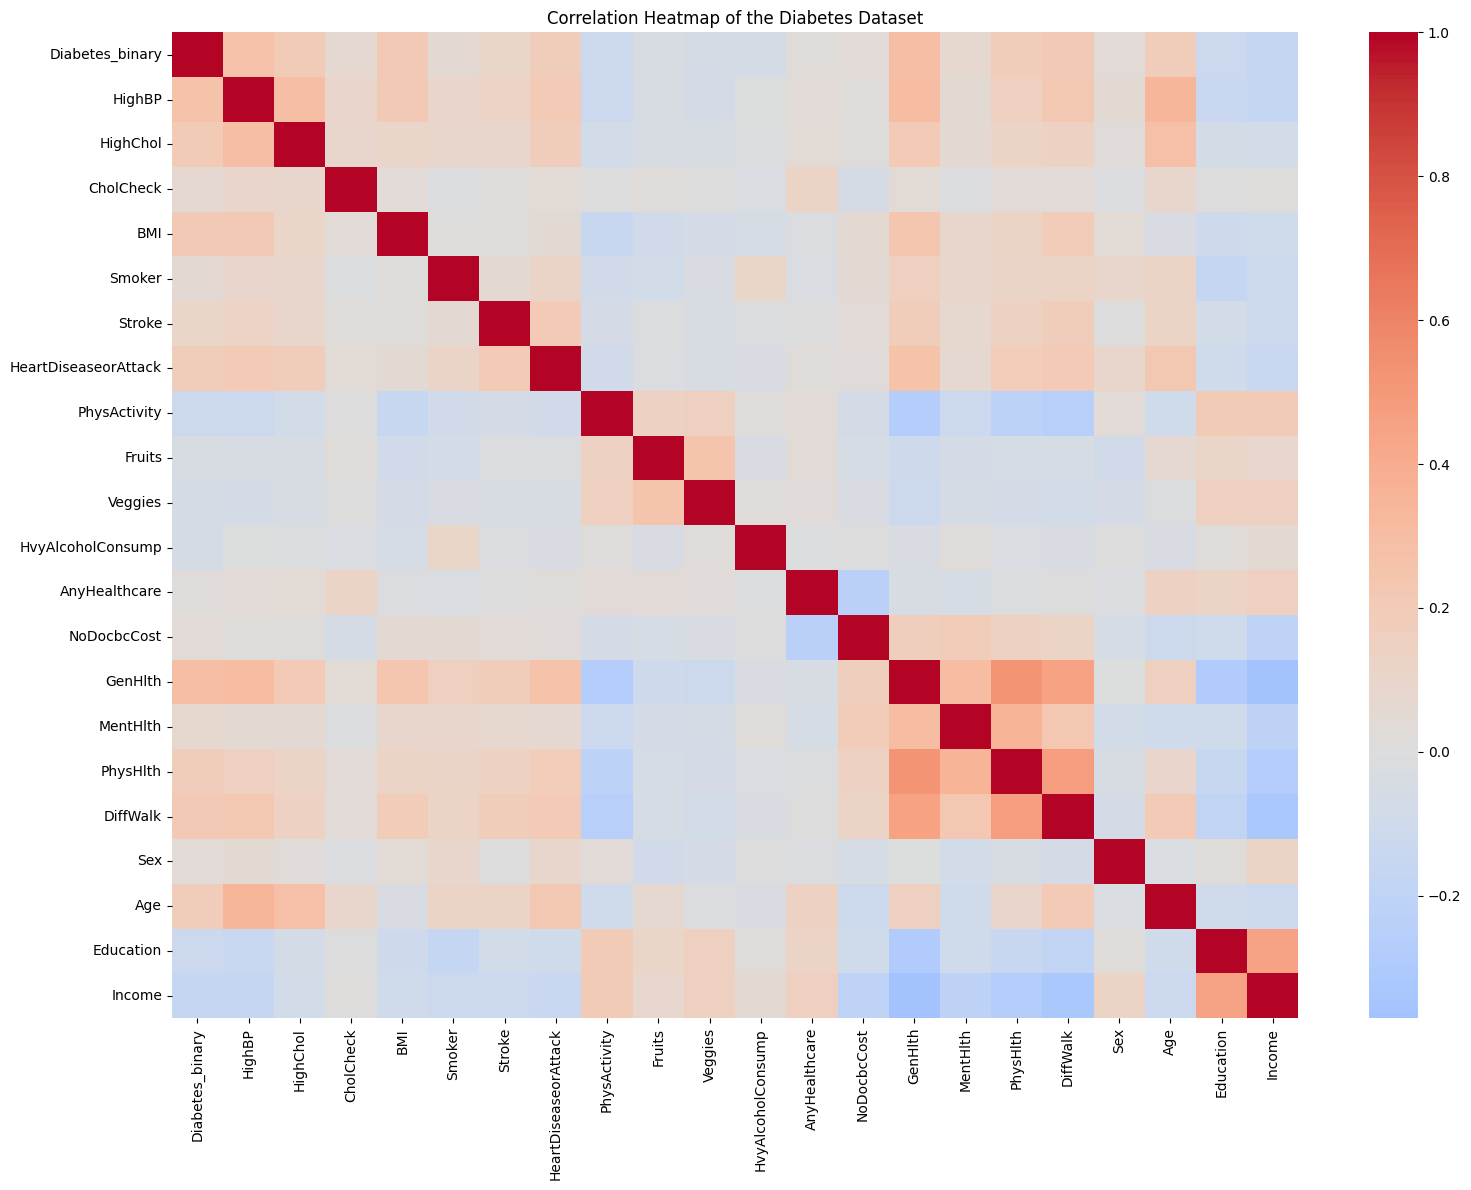

In [18]:
#CORRELATION HEATMAP

plt.figure(figsize=(16, 12))

correlation_matrix = df.corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap of the Diabetes Dataset")
plt.tight_layout()
plt.show()

### Identifying the feature types

In [20]:
# Continuous numerical features
continuous_features = [
    "BMI",
    "MentHlth",
    "PhysHlth"
]

# Ordinal categorical features
ordinal_features = [
    "Age",
    "Education",
    "Income",
    "GenHlth"
]

# Binary features
binary_features = [
    col for col in X.columns
    if col not in continuous_features + ordinal_features
]

print("The Continuous features are:", continuous_features)
print("\nThe Ordinal features are:", ordinal_features)
print("\nThe Binary features are:", binary_features)

print("\nThe Total features are:",
      len(continuous_features) +
      len(ordinal_features) +
      len(binary_features))

The Continuous features are: ['BMI', 'MentHlth', 'PhysHlth']

The Ordinal features are: ['Age', 'Education', 'Income', 'GenHlth']

The Binary features are: ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']

The Total features are: 21


### Performing Training and Test Data Split

In [22]:
from sklearn.model_selection import train_test_split

# Splitting the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data size:", X_train.shape)
print("Testing data size:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training data size: (202944, 21)
Testing data size: (50736, 21)

Training target distribution:
Diabetes_binary
0.0    0.860666
1.0    0.139334
Name: proportion, dtype: float64

Testing target distribution:
Diabetes_binary
0.0    0.860671
1.0    0.139329
Name: proportion, dtype: float64


### Creating the preprocessing pipeline

In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

# Scaling continuous and ordinal features
features_to_scale = continuous_features + ordinal_features

# Creating preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "scaler",
            StandardScaler(),
            features_to_scale
        )
    ],
    remainder="passthrough"
)

# Fitting preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformation to testing data
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing is completed successfully!")

print("Training data after preprocessing:",
      X_train_processed.shape)

print("Testing data after preprocessing:",
      X_test_processed.shape)

print("\nMissing values in training data:",
      np.isnan(X_train_processed).sum())

print("Missing values in testing data:",
      np.isnan(X_test_processed).sum())

Preprocessing is completed successfully!
Training data after preprocessing: (202944, 21)
Testing data after preprocessing: (50736, 21)

Missing values in training data: 0
Missing values in testing data: 0


### Importing the classification Models

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

print("All the required five classifier libraries imported!")

All the required five classifier libraries imported!


### Training the Five Models

In [28]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ),

    "Naive Bayes": GaussianNB(),

    "SVM": LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=3000
    )
}

trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train_processed, y_train)

    trained_models[name] = model

    print(name, "Model training completed!")

print("\nAll the five models have been trained successfully!")


Training: Logistic Regression
Logistic Regression Model training completed!

Training: Decision Tree
Decision Tree Model training completed!

Training: KNN
KNN Model training completed!

Training: Naive Bayes
Naive Bayes Model training completed!

Training: SVM
SVM Model training completed!

All the five models have been trained successfully!


### Performing the Model Evaluation using 6 different metrics

In [30]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

results = []

for name, model in trained_models.items():

    # Predict test results
    y_pred = model.predict(X_test_processed)

    # Obtain probability or decision scores for AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_processed)[:, 1]
    else:
        y_score = model.decision_function(X_test_processed)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(y_test, y_score)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

# Create comparison table
results_df = pd.DataFrame(results)

display(
    results_df.round(4).sort_values(
        by="F1 Score",
        ascending=False
    )
)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.7316,0.8196,0.3108,0.7608,0.4413,0.3563
4,SVM,0.7275,0.8194,0.3083,0.7686,0.4400,0.3559
1,Decision Tree,0.7040,0.8063,0.2917,0.7877,0.4258,0.3417
3,Naive Bayes,0.7722,0.7803,0.3198,0.5639,0.4082,0.2974
2,KNN,0.8490,0.7266,0.4193,0.2176,0.2865,0.2257


### Plotting all models by comparing each model against each metric

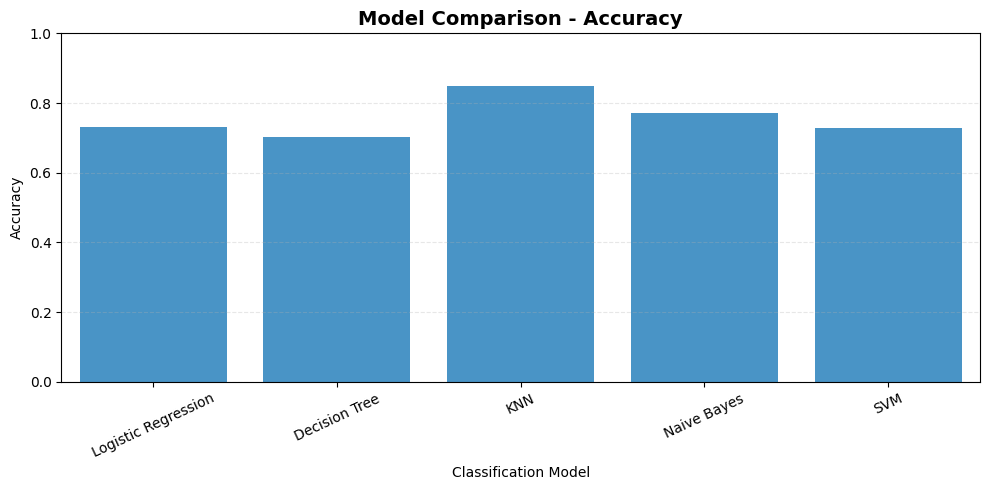

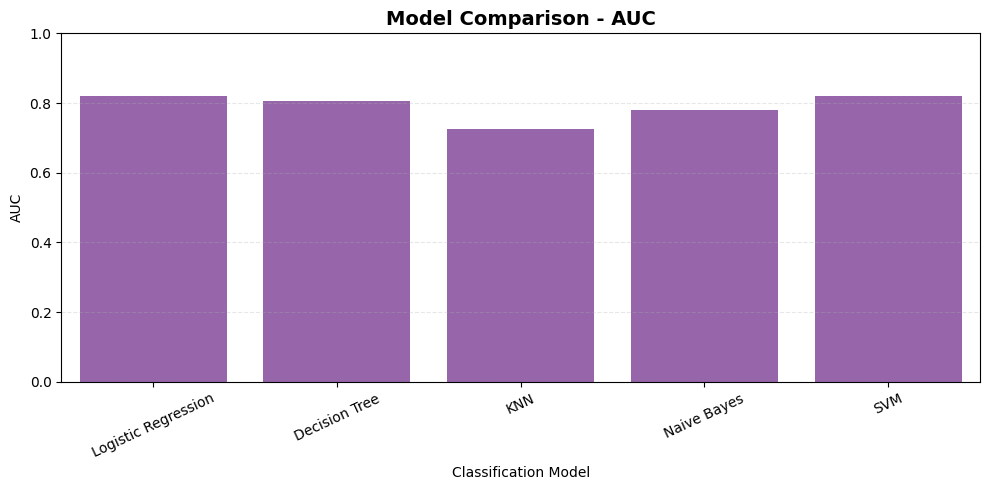

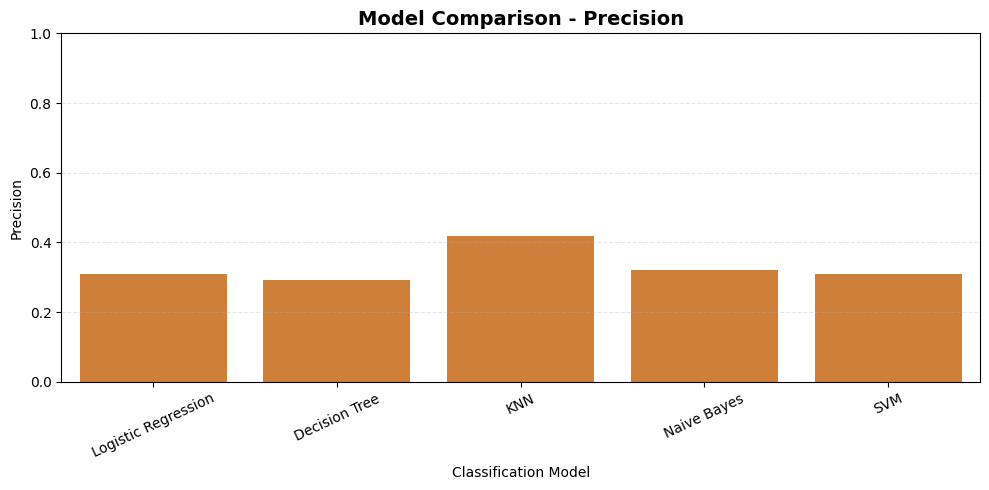

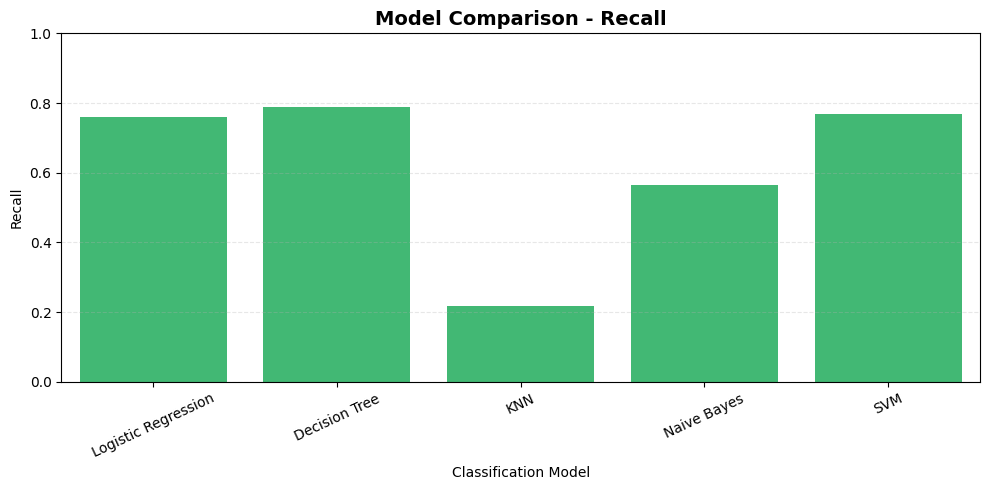

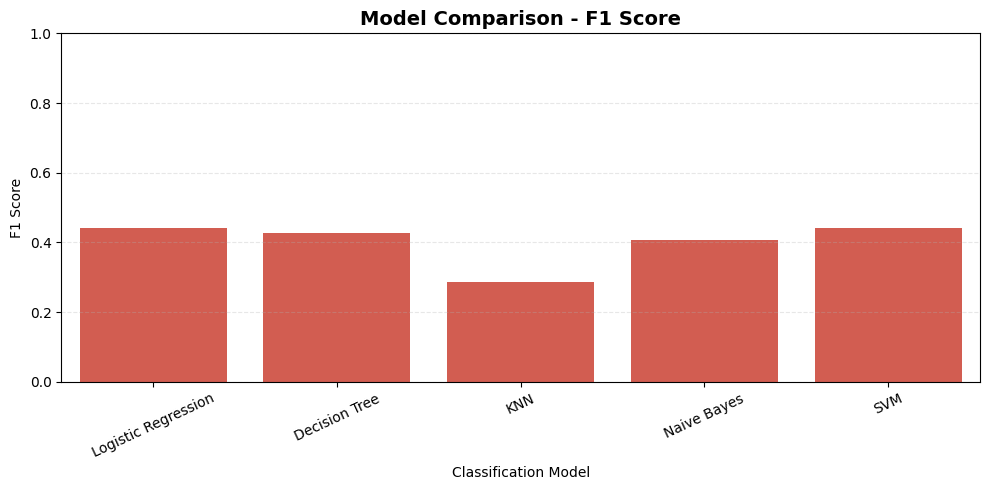

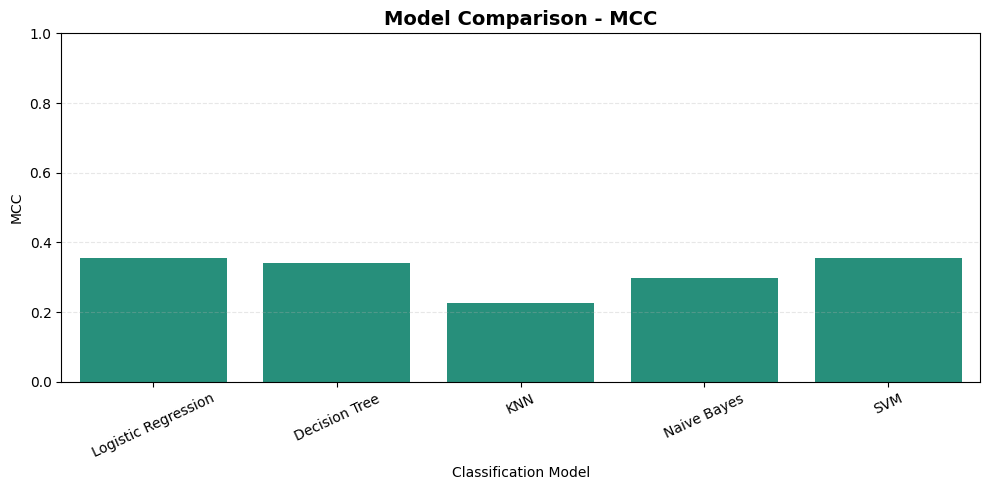

In [32]:
metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

# Different colour for each evaluation metric
metric_colors = {
    "Accuracy": "#3498DB",   # Blue
    "AUC": "#9B59B6",        # Purple
    "Precision": "#E67E22",  # Orange
    "Recall": "#2ECC71",     # Green
    "F1 Score": "#E74C3C",   # Red
    "MCC": "#16A085"         # Teal
}

for metric in metrics:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric,
        color=metric_colors[metric]
    )

    plt.title(
        "Model Comparison - " + metric,
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel("Classification Model")
    plt.ylabel(metric)

    plt.ylim(0, 1)
    plt.xticks(rotation=25)

    plt.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()

### Plotting the confusion matrix to understand the false negatives


Confusion Matrix for: Logistic Regression
[[31742 11925]
 [ 1691  5378]]


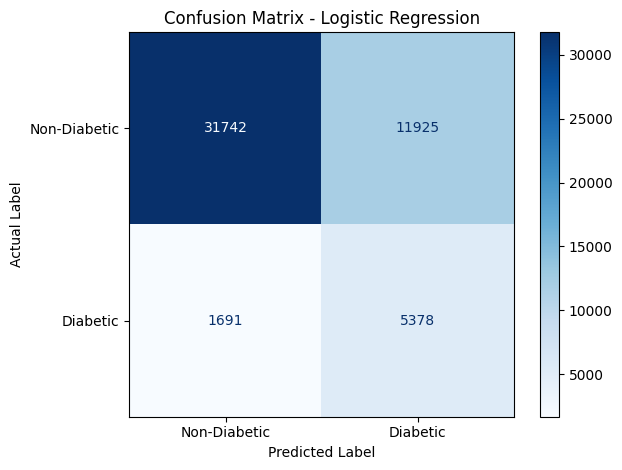


Confusion Matrix for: Decision Tree
[[30148 13519]
 [ 1501  5568]]


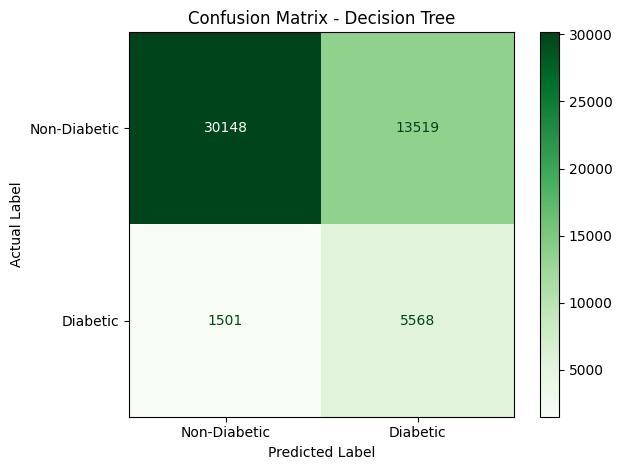


Confusion Matrix for: KNN
[[41537  2130]
 [ 5531  1538]]


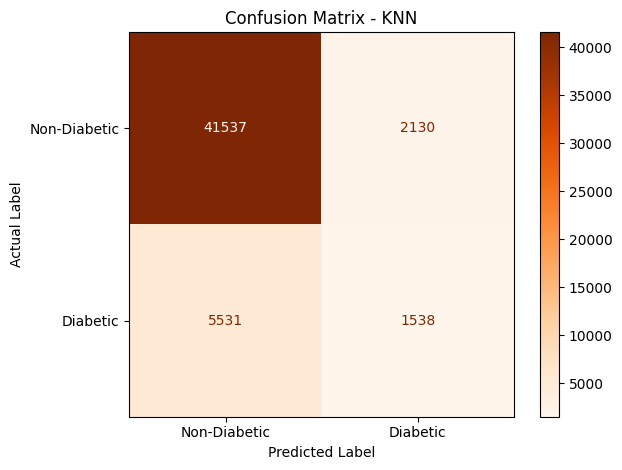


Confusion Matrix for: Naive Bayes
[[35190  8477]
 [ 3083  3986]]


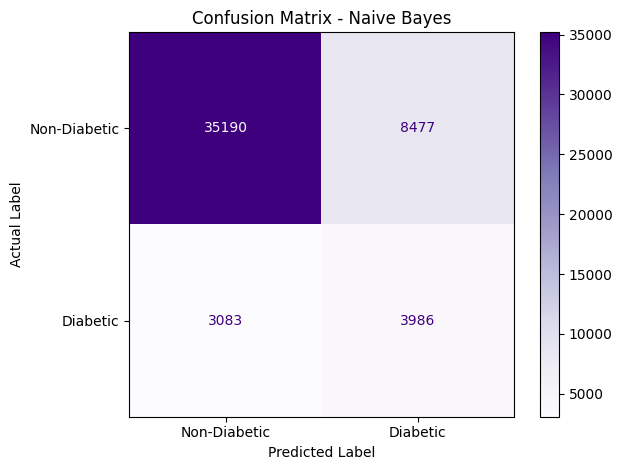


Confusion Matrix for: SVM
[[31475 12192]
 [ 1636  5433]]


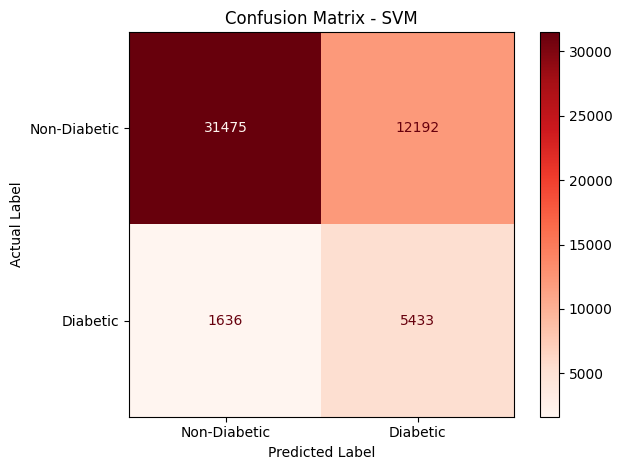

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Different colour schemes for each classification model
color_maps = {
    "Logistic Regression": "Blues",
    "Decision Tree": "Greens",
    "KNN": "Oranges",
    "Naive Bayes": "Purples",
    "SVM": "Reds"
}

# Generating confusion matrices for all five models
for model_name, model in trained_models.items():

    # Predicting the test data
    y_pred = model.predict(X_test_processed)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    print("\nConfusion Matrix for:", model_name)
    print(cm)

    # Select a different colour for each model
    cmap = color_maps.get(model_name, "Blues")

    # Display confusion matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-Diabetic", "Diabetic"]
    )

    disp.plot(
        cmap=cmap,
        values_format="d",
        colorbar=True
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

### Plotting the ROC Curve

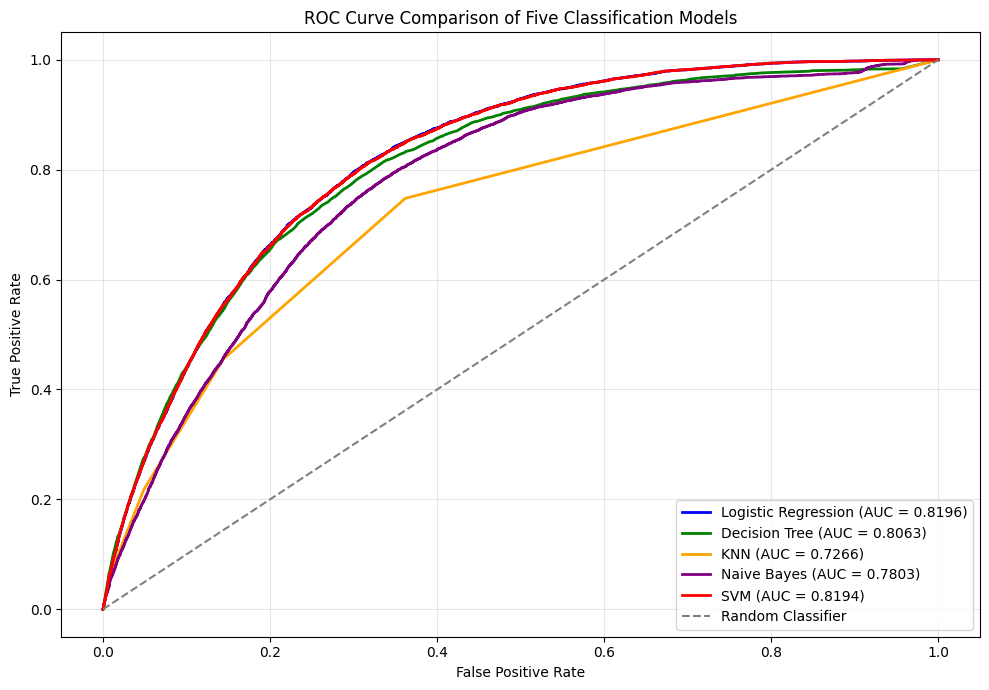

In [36]:
from sklearn.metrics import roc_curve, auc
# Different colours for each classification model
model_colors = {
    "Logistic Regression": "blue",
    "Decision Tree": "green",
    "KNN": "orange",
    "Naive Bayes": "purple",
    "SVM": "red"
}

plt.figure(figsize=(10, 7))

# Generating ROC curves for all five models
for model_name, model in trained_models.items():

    # Getting the prediction scores
    if hasattr(model, "predict_proba"):
        y_scores = model.predict_proba(X_test_processed)[:, 1]
    else:
        y_scores = model.decision_function(X_test_processed)

    # Calculating the FPR and TPR
    fpr, tpr, thresholds = roc_curve(y_test, y_scores)

    # Calculating the AUC
    roc_auc = auc(fpr, tpr)

    # Plotting the ROC curve
    plt.plot(
        fpr,
        tpr,
        color=model_colors.get(model_name, "black"),
        linewidth=2,
        label=f"{model_name} (AUC = {roc_auc:.4f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison of Five Classification Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Generating the classification reports for all models

In [38]:
from sklearn.metrics import classification_report

# Storing the classification reports for later comparison
classification_reports = {}

# Generating the reports for all five models
for model_name, model in trained_models.items():

    # Predicting the test data
    y_pred = model.predict(X_test_processed)

    # Generating classification report as a dictionary
    report_dict = classification_report(
        y_test,
        y_pred,
        target_names=["Non-Diabetic", "Diabetic"],
        output_dict=True,
        zero_division=0
    )

    # Storing the report for later analysis
    classification_reports[model_name] = report_dict

    # Displaying classification report
    print("\n" + "=" * 60)
    print("Classification Report:", model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Non-Diabetic", "Diabetic"],
            digits=4,
            zero_division=0
        )
    )

print("\nAll five classification reports generated and stored successfully!")



Classification Report: Logistic Regression
              precision    recall  f1-score   support

Non-Diabetic     0.9494    0.7269    0.8234     43667
    Diabetic     0.3108    0.7608    0.4413      7069

    accuracy                         0.7316     50736
   macro avg     0.6301    0.7438    0.6324     50736
weighted avg     0.8604    0.7316    0.7702     50736


Classification Report: Decision Tree
              precision    recall  f1-score   support

Non-Diabetic     0.9526    0.6904    0.8006     43667
    Diabetic     0.2917    0.7877    0.4258      7069

    accuracy                         0.7040     50736
   macro avg     0.6221    0.7390    0.6132     50736
weighted avg     0.8605    0.7040    0.7484     50736


Classification Report: KNN
              precision    recall  f1-score   support

Non-Diabetic     0.8825    0.9512    0.9156     43667
    Diabetic     0.4193    0.2176    0.2865      7069

    accuracy                         0.8490     50736
   macro avg     0

### Creating a comparison table to compare the diabetic-class performance across all five models.

In [40]:
class_report_results = []

for model_name, report in classification_reports.items():

    class_report_results.append({
        "Model": model_name,
        "Diabetic Precision": report["Diabetic"]["precision"],
        "Diabetic Recall": report["Diabetic"]["recall"],
        "Diabetic F1 Score": report["Diabetic"]["f1-score"],
        "Diabetic Support": report["Diabetic"]["support"]
    })

class_report_df = pd.DataFrame(class_report_results)

display(
    class_report_df.sort_values(
        by="Diabetic Recall",
        ascending=False
    ).round(4)
)

,Model,Diabetic Precision,Diabetic Recall,Diabetic F1 Score,Diabetic Support
1,Decision Tree,0.2917,0.7877,0.4258,7069.0
4,SVM,0.3083,0.7686,0.4400,7069.0
0,Logistic Regression,0.3108,0.7608,0.4413,7069.0
3,Naive Bayes,0.3198,0.5639,0.4082,7069.0
2,KNN,0.4193,0.2176,0.2865,7069.0


### Plotting the diabetic-class performance

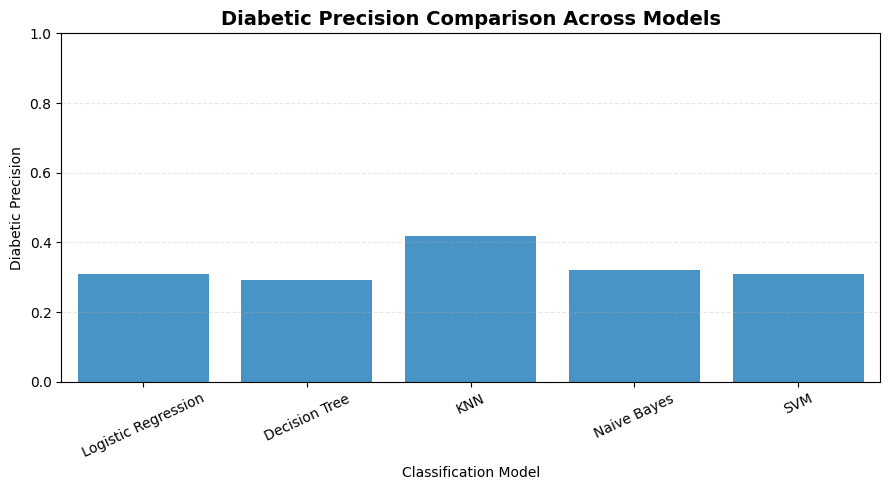

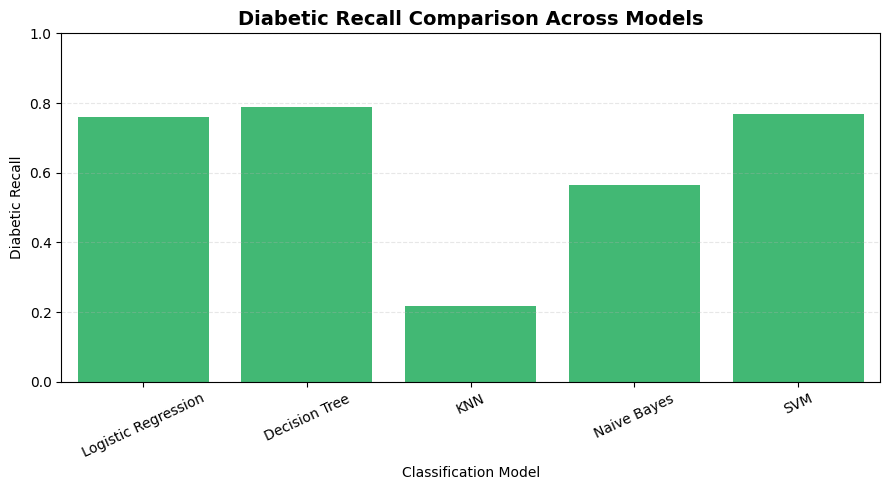

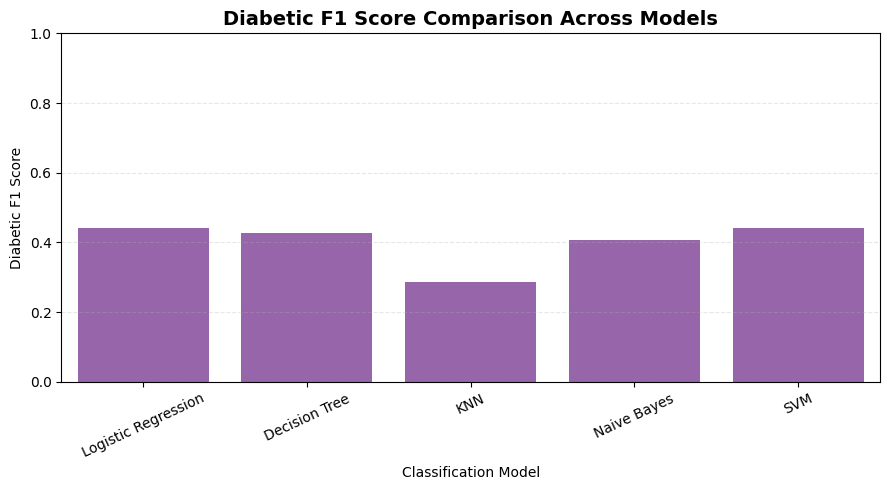

In [42]:
report_metrics = [
    "Diabetic Precision",
    "Diabetic Recall",
    "Diabetic F1 Score"
]

report_colors = {
    "Diabetic Precision": "#3498DB",
    "Diabetic Recall": "#2ECC71",
    "Diabetic F1 Score": "#9B59B6"
}

for metric in report_metrics:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=class_report_df,
        x="Model",
        y=metric,
        color=report_colors[metric]
    )

    plt.title(
        metric + " Comparison Across Models",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel("Classification Model")
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.xticks(rotation=25)
    plt.grid(axis="y", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

### Calculating training and prediction run time for each model

In [44]:
import time
from sklearn.base import clone

# Storing the runtime results
runtime_results = []

# Measuring the training and prediction time for each model
for model_name, model in trained_models.items():

    print(f"Measuring runtime for {model_name}...")

    # Creating a fresh copy so the original trained model is not modified
    model_copy = clone(model)

    # Measuring the training time
    start_time = time.perf_counter()

    model_copy.fit(X_train_processed, y_train)

    training_time = time.perf_counter() - start_time

    # Measuring the prediction time over multiple runs
    prediction_times = []

    for _ in range(3):

        start_time = time.perf_counter()

        model_copy.predict(X_test_processed)

        prediction_time = time.perf_counter() - start_time

        prediction_times.append(prediction_time)

    # Calculate average and standard deviation
    average_prediction_time = sum(prediction_times) / len(prediction_times)

    prediction_std = pd.Series(prediction_times).std(ddof=0)

    # Store results
    runtime_results.append({
        "Model": model_name,
        "Training Time (seconds)": training_time,
        "Average Prediction Time (seconds)": average_prediction_time,
        "Prediction Time Std (seconds)": prediction_std
    })

# Create runtime comparison DataFrame
runtime_df = pd.DataFrame(runtime_results)

# Sort by training time
runtime_df = runtime_df.sort_values(
    by="Training Time (seconds)"
).reset_index(drop=True)

print("\nRuntime Comparison of Classification Models")
display(runtime_df.round(4))


Measuring runtime for Logistic Regression...
Measuring runtime for Decision Tree...
Measuring runtime for KNN...
Measuring runtime for Naive Bayes...
Measuring runtime for SVM...

Runtime Comparison of Classification Models


,Model,Training Time (seconds),Average Prediction Time (seconds),Prediction Time Std (seconds)
0,KNN,0.0585,70.6983,6.8556
1,Naive Bayes,0.0968,0.0138,0.0023
2,Decision Tree,1.5165,0.0119,0.0003
3,SVM,1.9399,0.0019,0.0002
4,Logistic Regression,3.9088,0.0140,0.0035


### Creating a training-time comparison chart

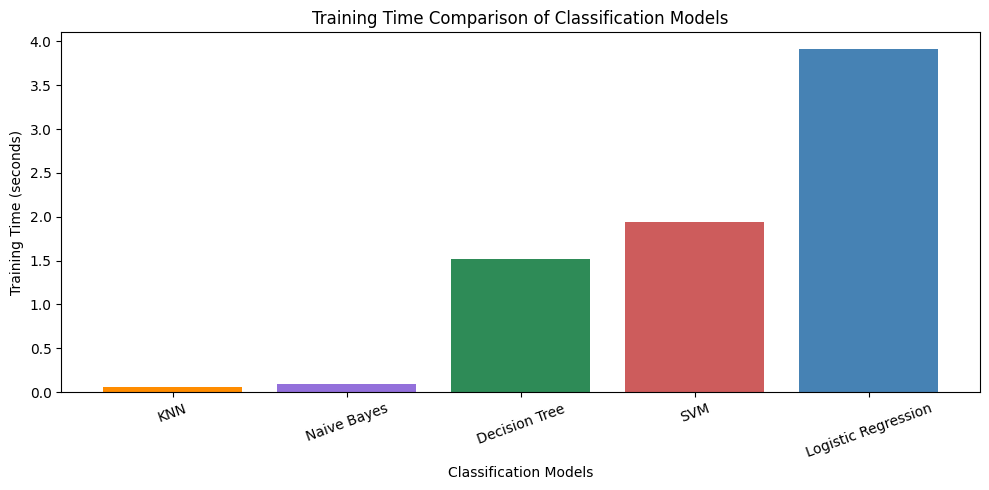

In [46]:
runtime_colors = {
    "Logistic Regression": "steelblue",
    "Decision Tree": "seagreen",
    "KNN": "darkorange",
    "Naive Bayes": "mediumpurple",
    "SVM": "indianred"
}

plt.figure(figsize=(10, 5))

plt.bar(
    runtime_df["Model"],
    runtime_df["Training Time (seconds)"],
    color=[runtime_colors[m] for m in runtime_df["Model"]]
)

plt.title("Training Time Comparison of Classification Models")
plt.xlabel("Classification Models")
plt.ylabel("Training Time (seconds)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Creating a prediction-time comparison chart

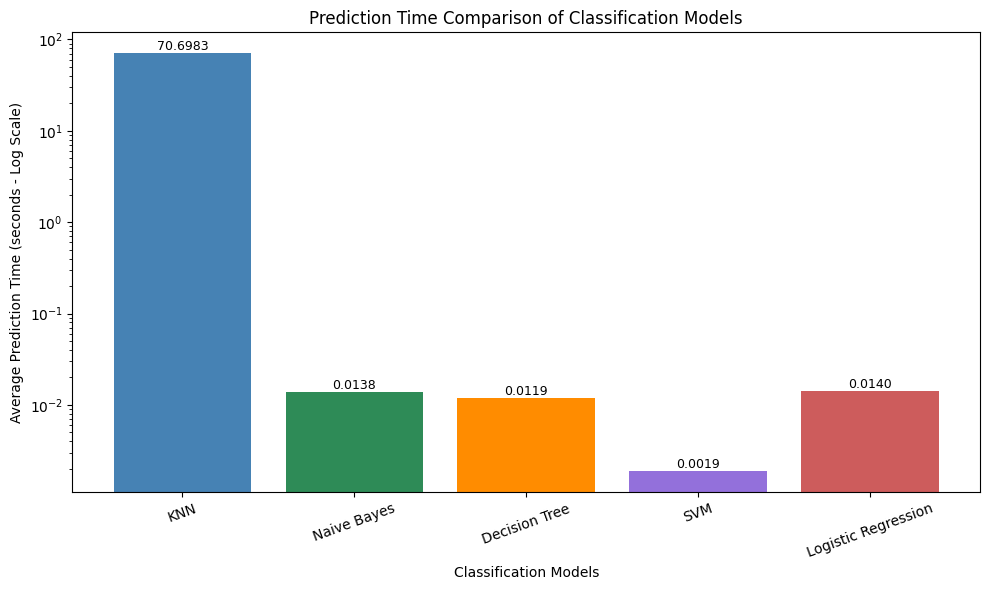

In [48]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    runtime_df["Model"],
    runtime_df["Average Prediction Time (seconds)"],
    color=["steelblue", "seagreen", "darkorange", "mediumpurple", "indianred"]
)

# Logarithmic scale makes smaller values easier to compare
plt.yscale("log")

# Displaying actual values above bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.4f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title("Prediction Time Comparison of Classification Models")
plt.xlabel("Classification Models")
plt.ylabel("Average Prediction Time (seconds - Log Scale)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()



#### Runtime Analysis

The runtime comparison shows differences in the computational efficiency of the five classification algorithms.

KNN recorded the lowest training time because it is a lazy-learning algorithm that stores training data rather than building a complex model during training. However, it required considerably more time for prediction because it calculates distances between test samples and stored training samples.

SVM recorded the highest training time among the five models in this experiment. Logistic Regression, Decision Tree, and Naive Bayes showed relatively lower prediction times compared with KNN.

This comparison demonstrates that training speed and prediction speed are different aspects of model efficiency. Therefore, both should be considered when selecting a classification algorithm.

### Adding a majority-class baseline

In [51]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Creating a majority-class baseline model
baseline_model = DummyClassifier(strategy="most_frequent")

# Training the baseline
baseline_model.fit(X_train_processed, y_train)

# Generating the predictions
baseline_predictions = baseline_model.predict(X_test_processed)

# Calculating the baseline accuracy
baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print("The Majority Class Baseline Accuracy:",
      round(baseline_accuracy, 4))

The Majority Class Baseline Accuracy: 0.8607


#### Observation: Majority-Class Baseline

A majority-class baseline classifier was evaluated to understand the effect of class imbalance. Since approximately 86.07% of the dataset belongs to the non-diabetic class, a classifier that always predicts the majority class can achieve approximately 86.07% accuracy.

This demonstrates that accuracy alone is not sufficient to assess the effectiveness of a classifier on an imbalanced dataset. Therefore, additional metrics such as precision, recall, F1 score, AUC and MCC are necessary for a more meaningful comparison.

### Performing the Final model comparison

In [54]:
# Sorting the models by F1 Score
final_comparison_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL PERFORMANCE COMPARISON")

display(final_comparison_df.round(4))

FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.7316,0.8196,0.3108,0.7608,0.4413,0.3563
1,SVM,0.7275,0.8194,0.3083,0.7686,0.4400,0.3559
2,Decision Tree,0.7040,0.8063,0.2917,0.7877,0.4258,0.3417
3,Naive Bayes,0.7722,0.7803,0.3198,0.5639,0.4082,0.2974
4,KNN,0.8490,0.7266,0.4193,0.2176,0.2865,0.2257


#### Model Performance Analysis

The performance comparison shows that Logistic Regression achieved the highest AUC (0.8196), F1 Score (0.4413), and MCC (0.3563), indicating a better balance between identifying diabetic and non-diabetic cases among the five models.

The Decision Tree achieved the highest recall (0.7877), making it more effective at identifying actual diabetic cases. KNN achieved the highest accuracy (0.8490) and precision (0.4191), but its recall was considerably lower (0.2174).

Since the dataset is imbalanced, accuracy alone is not sufficient to evaluate model performance. Therefore, AUC, F1 Score, Recall, and MCC are also considered when comparing the classifiers.

Overall, Logistic Regression provides the strongest balanced performance based on the evaluation metrics, while Decision Tree is preferable when prioritising recall.

### Identifying the best model for each metric

In [57]:
metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

print("BEST MODEL FOR EACH EVALUATION METRIC")

for metric in metrics:

    best_index = results_df[metric].idxmax()

    best_model = results_df.loc[best_index, "Model"]

    best_score = results_df.loc[best_index, metric]

    print(
        f"{metric}: {best_model} ({best_score:.4f})"
    )

BEST MODEL FOR EACH EVALUATION METRIC
Accuracy: KNN (0.8490)
AUC: Logistic Regression (0.8196)
Precision: KNN (0.4193)
Recall: Decision Tree (0.7877)
F1 Score: Logistic Regression (0.4413)
MCC: Logistic Regression (0.3563)


### Plotting the overall comparison against all evaluation metrics

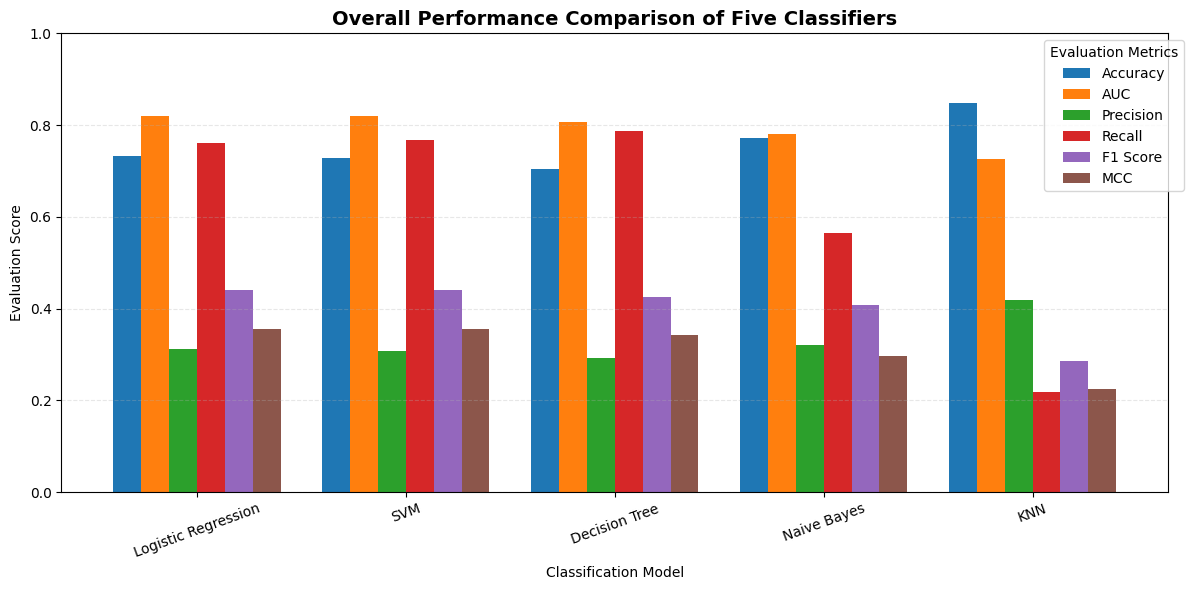

In [59]:
final_plot_df = final_comparison_df.set_index("Model")[metrics]

final_plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title(
    "Overall Performance Comparison of Five Classifiers",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Classification Model")
plt.ylabel("Evaluation Score")
plt.ylim(0, 1)

plt.xticks(rotation=20)
plt.legend(title="Evaluation Metrics", bbox_to_anchor=(1.02, 1))
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Creating a folder to save the models

In [61]:
import os

model_folder = "saved_models"

os.makedirs(model_folder, exist_ok=True)

print("Model folder created successfully!")

Model folder created successfully!


### Saving the preprocessing pipeline

In [63]:
import joblib

joblib.dump(preprocessor, "preprocessor.pkl")

print("The Preprocessor saved successfully!")

The Preprocessor saved successfully!


### Saving the feature order

In [65]:
import json

# Store the feature names in their original training order
feature_columns = X.columns.tolist()

with open("feature_columns.json", "w") as file:
    json.dump(feature_columns, file)

print("Feature order saved successfully!")

Feature order saved successfully!


### Saving all the five models

In [67]:
import joblib

for model_name, model in trained_models.items():

    # Convert model name into a filename
    filename = model_name.lower().replace(" ", "_") + ".pkl"

    file_path = os.path.join(model_folder, filename)

    # Save the trained model
    joblib.dump(model, file_path)

    print("Saved the model:", file_path)

Saved the model: saved_models/logistic_regression.pkl
Saved the model: saved_models/decision_tree.pkl
Saved the model: saved_models/knn.pkl
Saved the model: saved_models/naive_bayes.pkl
Saved the model: saved_models/svm.pkl


### Verifiying the saved models files

In [69]:
print("Saved all the model files:")

for filename in os.listdir(model_folder):
    print(filename)

Saved all the model files:
logistic_regression.pkl
decision_tree.pkl
knn.pkl
naive_bayes.pkl
svm.pkl


### Making sure the saved model runs without any error

In [71]:
print("Verifying all saved models...\n")

for model_name, model in trained_models.items():

    filename = (
        model_name.lower().replace(" ", "_") + ".pkl"
    )

    file_path = os.path.join(model_folder, filename)

    # Load the saved model
    loaded_model = joblib.load(file_path)

    # Generate predictions using sample test records
    predictions = loaded_model.predict(
        X_test_processed[:5]
    )

    print("Model:", model_name)
    print("Sample predictions:", predictions)
    print("Verification successful!\n")

Verifying all saved models...

Model: Logistic Regression
Sample predictions: [0. 1. 0. 0. 1.]
Verification successful!

Model: Decision Tree
Sample predictions: [1. 1. 0. 0. 1.]
Verification successful!

Model: KNN
Sample predictions: [0. 0. 0. 0. 0.]
Verification successful!

Model: Naive Bayes
Sample predictions: [0. 1. 0. 0. 1.]
Verification successful!

Model: SVM
Sample predictions: [1. 1. 0. 0. 1.]
Verification successful!



### Creating a separate test dataset for Streamlit testing

In [112]:
test_data = X_test.copy()

# Add the actual target column
test_data["Diabetes_binary"] = y_test

# Save the test dataset
test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved successfully!")
print("Test dataset shape:", test_data.shape)

display(test_data.head())


Test dataset saved successfully!
Test dataset shape: (50736, 22)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
128677,1.0,1.0,1.0,28.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,3.0,0.0,0.0,0.0,1.0,5.0,5.0,8.0,0.0
225051,1.0,0.0,1.0,36.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,3.0,0.0,0.0,1.0,0.0,10.0,3.0,4.0,1.0
27174,0.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,2.0,0.0,0.0,0.0,0.0,5.0,5.0,8.0,0.0
132371,0.0,0.0,1.0,22.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,2.0,0.0,0.0,0.0,0.0,11.0,4.0,7.0,0.0
164896,1.0,1.0,1.0,26.0,1.0,0.0,1.0,1.0,1.0,1.0,...,0.0,4.0,0.0,7.0,0.0,0.0,13.0,5.0,2.0,1.0
